# Time-Varying Volatility and the Sustainability of Covered-Call ETF Income

**Module:** Financial Analytics — Individual Assignment  
**Article extended:** S. Johnson, "Retail investors turn to 'options income' ETFs in search for yield", *Financial Times*, 21 May 2026.  
**Module topic:** Time-Varying Volatility (ARCH / GARCH / GJR-GARCH; volatility forecasting; Black-Scholes link).

> **Note on module code:** confirm your exact module code from the student handbook before submission.

**Logic of the extension.** Covered-call ('options income') ETFs generate yield by *selling* call options. The premium received is, via Black-Scholes (lecture slide 17), an increasing function of the underlying's volatility. The article claims income is (i) higher on volatile assets, (ii) 'uneven', and (iii) unsustainable when very high. All three are claims about **time-varying volatility**. We model the conditional volatility of two underlyings spanning a volatility spectrum — S&P 500 (index) and Tesla (high-vol single stock, named in the article) — using GARCH(1,1) and GJR-GARCH(1,1) with **Student-t innovations** (justified by the heavy tails we document), inspect the **leverage parameter**, run a **rolling 10-day-ahead forecast horse-race**, and translate forecast volatility into a stylised 'sustainable' premium yield. A short supporting section compares actual covered-call ETFs for context.

> **AI use declaration (does NOT count toward word limit).** Generative AI (Claude, Anthropic) was used to structure the analysis, draft and debug this notebook, and check the mapping between article claims and module techniques. All modelling choices, interpretation, and final writing are my own; outputs were verified against the lecture materials. Records of interactions retained.

In [1]:
# ---------- 0. Install & import ----------
import sys, subprocess, warnings
warnings.filterwarnings('ignore')

for pkg in ['yfinance', 'arch', 'statsmodels', 'scipy', 'matplotlib', 'pandas', 'numpy']:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats
from scipy.stats import norm
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
np.random.seed(42)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. Data Collection

Two **underlyings** (the objects whose volatility prices the premium) plus a small set of **covered-call ETFs** for the supporting comparison. Robust to recent `yfinance` multi-index columns and to individual ticker failures.

In [2]:
START, END = '2016-01-01', '2026-05-22'

underlying_tickers = {'S&P 500': '^GSPC', 'Tesla': 'TSLA'}
etf_tickers        = {'JEPI': 'JEPI', 'QYLD': 'QYLD', 'XYLD': 'XYLD'}
all_tickers = {**underlying_tickers, **etf_tickers}

def get_close(ticker):
    df = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)
    if df.empty:
        return None
    # recent yfinance returns MultiIndex columns even for a single ticker
    if isinstance(df.columns, pd.MultiIndex):
        return df['Close'].iloc[:, 0]
    return df['Close']

prices = {}
for name, tk in all_tickers.items():
    s = get_close(tk)
    if s is None:
        print(f'WARNING: no data for {name} ({tk})')
    else:
        prices[name] = s
        print(f'Downloaded: {name}')

prices = pd.DataFrame(prices)
print('\nShape:', prices.shape)
prices.tail()

Downloaded: S&P 500
Downloaded: Tesla
Downloaded: JEPI
Downloaded: QYLD
Downloaded: XYLD

Shape: (2611, 5)


,S&P 500,Tesla,JEPI,QYLD,XYLD
Date,,,,,
2026-05-15,"7,408.5000",422.2400,55.5020,17.7110,40.1190
2026-05-18,"7,403.0498",409.9900,55.7404,17.7100,40.1600
2026-05-19,"7,353.6099",404.1100,55.6907,17.6500,40.0400
2026-05-20,"7,432.9702",417.2600,55.7900,17.8000,40.2700
2026-05-21,"7,445.7202",417.8500,55.6907,17.8400,40.3600


In [3]:
# ---------- Log returns (slide 2); scale by 100 for the MLE optimiser ----------
# Underlyings need a long aligned history for GARCH; ETFs handled separately later.
underlying_prices = prices[list(underlying_tickers.keys())].dropna()
returns = 100 * np.log(underlying_prices / underlying_prices.shift(1))
returns = returns.dropna()

assert not returns.isna().any().any()
print('Underlying returns:', returns.index.min().date(), '->', returns.index.max().date(), '| obs:', len(returns))
returns.tail()

Underlying returns: 2016-01-05 -> 2026-05-21 | obs: 2610


,S&P 500,Tesla
Date,,
2026-05-15,-1.2440,-4.8673
2026-05-18,-0.0736,-2.9441
2026-05-19,-0.6701,-1.4446
2026-05-20,1.0734,3.2022
2026-05-21,0.1714,0.1413


## 2. Exploratory Analysis ("Always look at the data" — slide 5)

Check the stylised facts (slide 2): little autocorrelation in returns, heavy tails (slide 7), volatility clustering (slide 3).

In [4]:
summary = pd.DataFrame({
    'Mean daily %':     returns.mean(),
    'Daily vol %':      returns.std(),
    'Ann. vol %':       returns.std() * np.sqrt(252),
    'Skewness':         returns.skew(),
    'Excess kurtosis':  returns.kurtosis(),
    'Min %':            returns.min(),
    'Max %':            returns.max(),
})
display(summary)
most_volatile = summary['Daily vol %'].idxmax()
print('Most volatile underlying ->', most_volatile)

,Mean daily %,Daily vol %,Ann. vol %,Skewness,Excess kurtosis,Min %,Max %
S&P 500,0.0501,1.1360,18.0328,-0.6756,16.5177,-12.7652,9.0895
Tesla,0.1277,3.6838,58.4786,-0.0543,4.2574,-23.6518,20.4491


Most volatile underlying -> Tesla


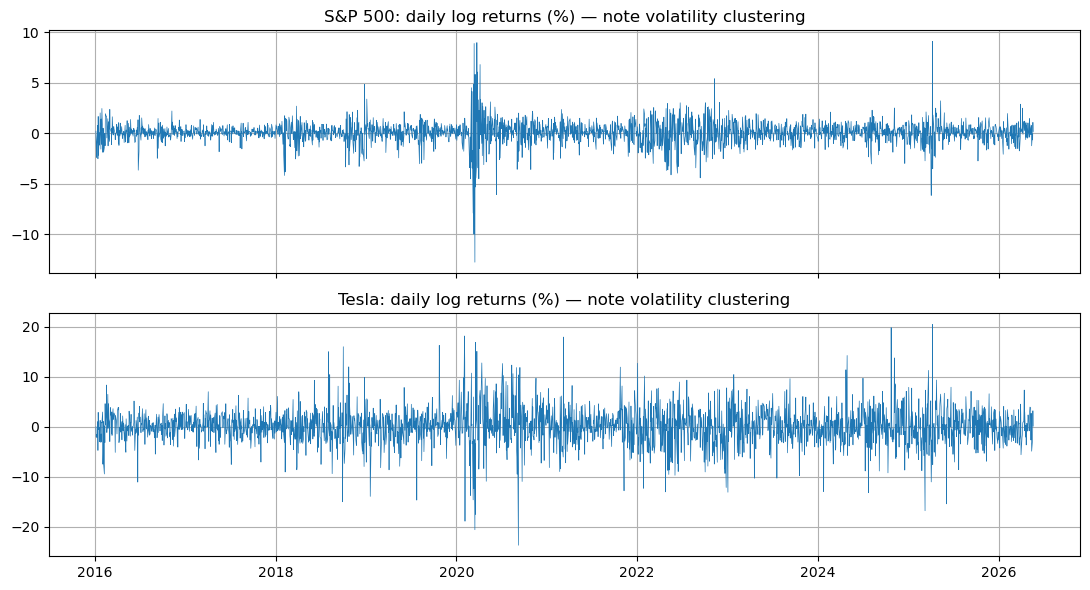

In [5]:
fig, axes = plt.subplots(len(returns.columns), 1, figsize=(11, 6), sharex=True)
for ax, col in zip(np.atleast_1d(axes), returns.columns):
    ax.plot(returns.index, returns[col], lw=0.5)
    ax.set_title(f'{col}: daily log returns (%) — note volatility clustering')
plt.tight_layout(); plt.show()

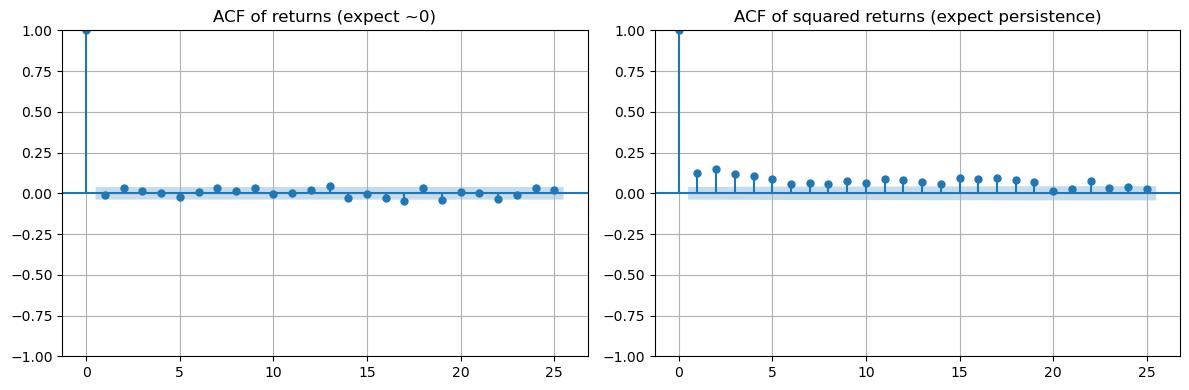

,Asset,LB stat (lag 10),p-value
0,S&P 500,"2,830.9005",0.0000
1,Tesla,233.9555,0.0000


Low p-value -> autocorrelation in squared returns -> volatility clustering -> GARCH justified.


In [6]:
# Clustering diagnostics + heavy-tail check on the most volatile series
r = returns[most_volatile]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(r, lags=25, ax=axes[0]);    axes[0].set_title('ACF of returns (expect ~0)')
plot_acf(r**2, lags=25, ax=axes[1]); axes[1].set_title('ACF of squared returns (expect persistence)')
plt.tight_layout(); plt.show()

# Ljung-Box on squared returns for ALL underlyings -> formal ARCH-effects test
lb_rows = []
for col in returns.columns:
    t = acorr_ljungbox(returns[col]**2, lags=[10], return_df=True)
    lb_rows.append({'Asset': col, 'LB stat (lag 10)': t['lb_stat'].iloc[0], 'p-value': t['lb_pvalue'].iloc[0]})
display(pd.DataFrame(lb_rows))
print('Low p-value -> autocorrelation in squared returns -> volatility clustering -> GARCH justified.')

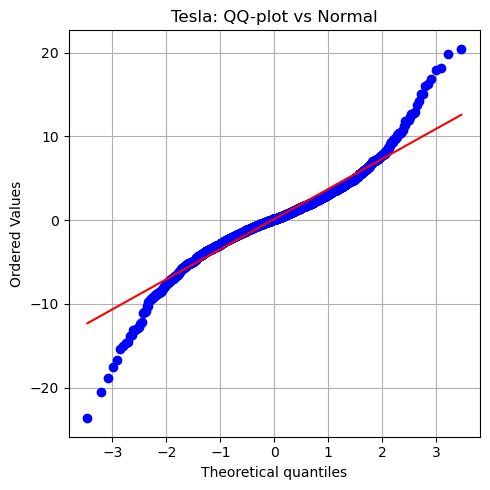

Jarque-Bera (H0: normal): stat=1962.7, p=0  -> reject normality -> use dist=t


In [7]:
# QQ-plot + Jarque-Bera: motivates Student-t innovations ('normal is not normal', slide 7)
fig, ax = plt.subplots(figsize=(5, 5))
stats.probplot(r, dist='norm', plot=ax)
ax.set_title(f'{most_volatile}: QQ-plot vs Normal')
plt.tight_layout(); plt.show()
jb = stats.jarque_bera(r)
print(f'Jarque-Bera (H0: normal): stat={jb[0]:.1f}, p={jb[1]:.3g}  -> reject normality -> use dist=t')

## 3. Model Fitting: GARCH(1,1) vs GJR-GARCH(1,1) — Student-t innovations

Constant mean (returns have little autocorrelation), **Student-t** innovations (consistent with the heavy tails just documented — fixing the earlier Gaussian inconsistency), MLE estimation, following the slide-13 workflow. GJR adds the leverage term (slide 18):
$$\sigma_t^2 = \omega + \alpha a_{t-1}^2 + \theta\,\mathbb{1}_{\{a_{t-1}<0\}} a_{t-1}^2 + \beta\sigma_{t-1}^2.$$

In [8]:
model_results = {}
for asset in returns.columns:
    r_a = returns[asset].dropna()
    garch = arch_model(r_a, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off')
    gjr   = arch_model(r_a, mean='Constant', vol='GARCH', p=1, o=1, q=1, dist='t').fit(disp='off')
    model_results[asset] = {'GARCH': garch, 'GJR-GARCH': gjr}
    print(f'\n===== {asset} =====')
    print(f"GARCH(1,1)     AIC={garch.aic:.1f}  BIC={garch.bic:.1f}  LLF={garch.loglikelihood:.1f}")
    print(f"GJR-GARCH(1,1) AIC={gjr.aic:.1f}  BIC={gjr.bic:.1f}  LLF={gjr.loglikelihood:.1f}")


===== S&P 500 =====
GARCH(1,1)     AIC=6529.0  BIC=6558.3  LLF=-3259.5
GJR-GARCH(1,1) AIC=6456.1  BIC=6491.3  LLF=-3222.1

===== Tesla =====
GARCH(1,1)     AIC=13611.3  BIC=13640.7  LLF=-6800.7
GJR-GARCH(1,1) AIC=13612.6  BIC=13647.8  LLF=-6800.3


In [9]:
# Full summaries for the most volatile series
print('--- GARCH(1,1) ---');     print(model_results[most_volatile]['GARCH'].summary())
print('\n--- GJR-GARCH(1,1) ---'); print(model_results[most_volatile]['GJR-GARCH'].summary())

--- GARCH(1,1) ---
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                        Tesla   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -6800.67
Distribution:      Standardized Student's t   AIC:                           13611.3
Method:                  Maximum Likelihood   BIC:                           13640.7
                                              No. Observations:                 2610
Date:                      Tue, Jun 09 2026   Df Residuals:                     2609
Time:                              22:26:23   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
------------------------------------------------------------------

In [10]:
# ---------- Parameter table: persistence, long-run vol, AND leverage theta (H2) ----------
# In arch's GJR parameterisation the leverage term is 'gamma[1]'.
rows = []
for asset, m in model_results.items():
    g, j = m['GARCH'], m['GJR-GARCH']
    gp = g.params
    persist = gp['alpha[1]'] + gp['beta[1]']
    VL_daily = np.sqrt(gp['omega'] / (1 - persist))           # long-run daily vol (slide 16)
    theta = j.params['gamma[1]']
    theta_t = j.tvalues['gamma[1]']                            # significance of leverage
    rows.append({'Asset': asset,
                 'alpha': gp['alpha[1]'], 'beta': gp['beta[1]'],
                 'persistence a+b': persist,
                 'ann. long-run vol %': VL_daily * np.sqrt(252),
                 'GJR leverage theta': theta, 'theta t-stat': theta_t})
param_tbl = pd.DataFrame(rows).set_index('Asset')
display(param_tbl)
print('H2: theta > 0 and significant (|t|>~2) => bad news raises volatility more than good news.')
print('Compare theta across underlyings: larger for the single stock supports the article\'s')
print('caution that single-stock covered-call funds are riskier.')

,alpha,beta,persistence a+b,ann. long-run vol %,GJR leverage theta,theta t-stat
Asset,,,,,,
S&P 500,0.1630,0.8334,0.9964,37.0360,0.2434,6.1215
Tesla,0.0395,0.9548,0.9944,66.3518,0.0086,0.8077


H2: theta > 0 and significant (|t|>~2) => bad news raises volatility more than good news.
Compare theta across underlyings: larger for the single stock supports the article's
caution that single-stock covered-call funds are riskier.


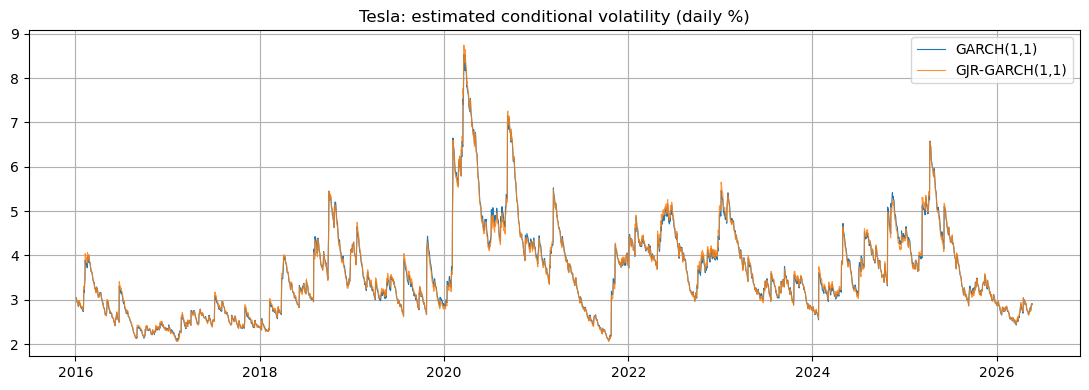

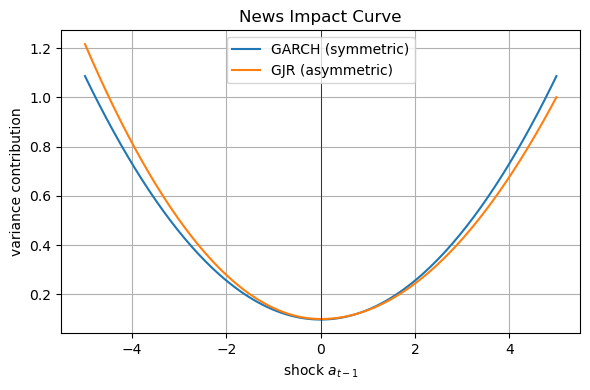

In [11]:
# Conditional volatility paths + news-impact curve (visualises the asymmetry)
g = model_results[most_volatile]['GARCH']
j = model_results[most_volatile]['GJR-GARCH']

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(g.conditional_volatility, label='GARCH(1,1)', lw=0.8)
ax.plot(j.conditional_volatility, label='GJR-GARCH(1,1)', lw=0.8, alpha=0.85)
ax.set_title(f'{most_volatile}: estimated conditional volatility (daily %)'); ax.legend()
plt.tight_layout(); plt.show()

shocks = np.linspace(-5, 5, 200)
gp, jp = g.params, j.params
ni_g   = gp['omega'] + gp['alpha[1]']*shocks**2
ni_gjr = jp['omega'] + jp['alpha[1]']*shocks**2 + jp['gamma[1]']*(shocks < 0)*shocks**2
plt.figure(figsize=(6, 4))
plt.plot(shocks, ni_g, label='GARCH (symmetric)')
plt.plot(shocks, ni_gjr, label='GJR (asymmetric)')
plt.axvline(0, color='k', lw=0.5)
plt.title('News Impact Curve'); plt.xlabel('shock $a_{t-1}$'); plt.ylabel('variance contribution'); plt.legend()
plt.tight_layout(); plt.show()

## 4. Forecast Horse-Race: rolling 10-day-ahead average volatility

This is the core out-of-sample deliverable (task spec slide 4). Walk-forward: re-fit periodically, forecast the **average** variance over the next 10 days, and score each model against **realised** volatility (std of the next 10 actual returns) using RMSE and QLIKE. QLIKE is robust to the noisy variance proxy.

In [12]:
def rolling_horserace(series, horizon=10, refit_every=20, start_frac=0.7):
    n = len(series); start = int(n * start_frac)
    recs = []; g_model = j_model = None
    for t in range(start, n - horizon):
        if (t - start) % refit_every == 0:
            train = series.iloc[:t]
            g_model = arch_model(train, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off')
            j_model = arch_model(train, mean='Constant', vol='GARCH', p=1, o=1, q=1, dist='t').fit(disp='off')
        fg = g_model.forecast(horizon=horizon, reindex=False)
        fj = j_model.forecast(horizon=horizon, reindex=False)
        recs.append({'date': series.index[t],
                     'realised': np.sqrt(series.iloc[t:t+horizon].var()),
                     'GARCH':    np.sqrt(fg.variance.values[-1].mean()),
                     'GJR':      np.sqrt(fj.variance.values[-1].mean())})
    return pd.DataFrame(recs).set_index('date')

hr = rolling_horserace(returns[most_volatile])
hr.tail()

,realised,GARCH,GJR
date,,,
2026-05-01,2.2242,3.0418,3.0294
2026-05-04,2.9629,3.0418,3.0294
2026-05-05,3.1898,3.0418,3.0294
2026-05-06,3.2237,3.0418,3.0294
2026-05-07,3.2907,3.0418,3.0294


Horse-race on Tesla (10-day-ahead average volatility, out-of-sample):
  GARCH   RMSE=1.3563   QLIKE=3.5389
  GJR     RMSE=1.3493   QLIKE=3.5375


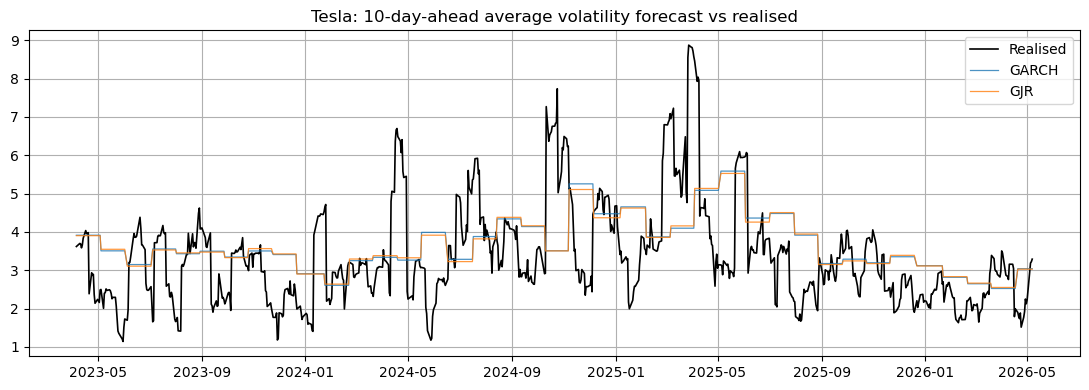

Lower RMSE/QLIKE wins. If GJR wins on the volatile series, asymmetry matters for forecasting it.


In [13]:
def qlike(realised_var, forecast_var):
    return np.mean(np.log(forecast_var) + realised_var / forecast_var)

print(f'Horse-race on {most_volatile} (10-day-ahead average volatility, out-of-sample):')
for m in ['GARCH', 'GJR']:
    rmse = np.sqrt(np.mean((hr[m] - hr['realised'])**2))
    ql   = qlike(hr['realised']**2, hr[m]**2)
    print(f'  {m:6s}  RMSE={rmse:.4f}   QLIKE={ql:.4f}')

plt.figure(figsize=(11, 4))
plt.plot(hr.index, hr['realised'], label='Realised', lw=1.2, color='k')
plt.plot(hr.index, hr['GARCH'], label='GARCH', lw=0.9, alpha=0.8)
plt.plot(hr.index, hr['GJR'],   label='GJR',   lw=0.9, alpha=0.8)
plt.title(f'{most_volatile}: 10-day-ahead average volatility forecast vs realised')
plt.legend(); plt.tight_layout(); plt.show()
print('Lower RMSE/QLIKE wins. If GJR wins on the volatile series, asymmetry matters for forecasting it.')

## 5. From Forecast Volatility to a 'Sustainable' Premium Yield

Connects the modelling to the article's economic claim. For a 1-month at-the-money covered call ($S_0=K$), the Black-Scholes premium-to-price ratio is reported two ways and **annualised by compounding** (fixing the earlier linear ×12). We compare the implied yield at *current* forecast volatility vs at *long-run* volatility $V_L$ — the gap is the part of headline yield that is **not** sustainable, because volatility mean-reverts toward $V_L$ (slide 16). Stylised, illustrative — see caveats below.

In [14]:
def bs_call(S, K, T, r, sigma):
    if sigma <= 0 or T <= 0:
        return np.nan
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

RFR = 0.045
T_MONTH = 1/12

rows = []
for asset, m in model_results.items():
    g = m['GARCH']
    gp = g.params
    persist = gp['alpha[1]'] + gp['beta[1]']
    VL_daily  = np.sqrt(gp['omega'] / (1 - persist))
    cur_daily = g.conditional_volatility.iloc[-1]
    S = underlying_prices[asset].dropna().iloc[-1]
    K = S  # at-the-money
    for label, sig_daily in [('current', cur_daily), ('long-run', VL_daily)]:
        sig_ann = sig_daily/100 * np.sqrt(252)
        monthly = bs_call(S, K, T_MONTH, RFR, sig_ann) / S
        annual_compounded = (1 + monthly)**12 - 1   # FIX: compound, not linear x12
        rows.append({'Underlying': asset, 'vol regime': label,
                     'ann. vol used %': sig_ann*100,
                     'monthly premium yield %': monthly*100,
                     'annualised (compounded) %': annual_compounded*100})
yield_tbl = pd.DataFrame(rows).set_index(['Underlying', 'vol regime'])
display(yield_tbl)
print('Gap between current and long-run annualised yield = the unsustainable component of headline yield.')

ann. vol used %  monthly premium yield %  \
Underlying vol regime                                             
S&P 500    current             13.4005                   1.7347   
           long-run            37.0360                   4.4450   
Tesla      current             46.0551                   5.4793   
           long-run            66.3518                   7.8040   

                       annualised (compounded) %  
Underlying vol regime                             
S&P 500    current                       22.9213  
           long-run                      68.5200  
Tesla      current                       89.6746  
           long-run                     146.3887

Gap between current and long-run annualised yield = the unsustainable component of headline yield.


**Caveats (the approximation deliberately ignores):** fund fees, strike selection, maturity choice, dividends, taxes, transaction costs, rolling rules, early exercise, the difference between realised-GARCH and *implied* volatility, capped upside, and capital losses in the underlying. It shows only the *mechanism* — higher expected volatility → richer premiums — not an actual ETF yield.

## 6. Supporting context: actual covered-call ETFs

*Not a time-varying-volatility technique — included as illustrative context for the article's instruments.* Compares realised return, volatility, and drawdowns of real covered-call ETFs. Frame this in the report as supporting colour, not core method.

,Mean daily %,Ann. return %,Ann. vol %,Skewness,Excess kurtosis
JEPI,0.0416,10.4784,10.8205,-0.1690,12.0163
QYLD,0.0394,9.9206,14.6448,0.0253,14.8341
XYLD,0.0409,10.3193,11.2707,0.0196,21.3394


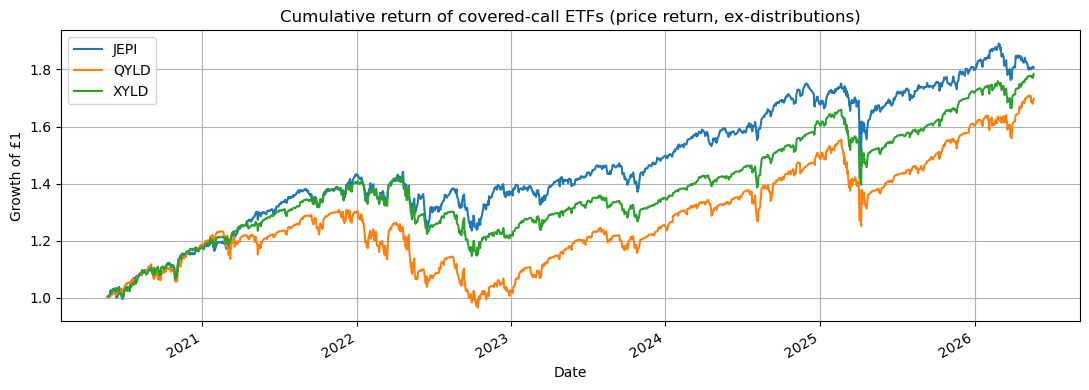

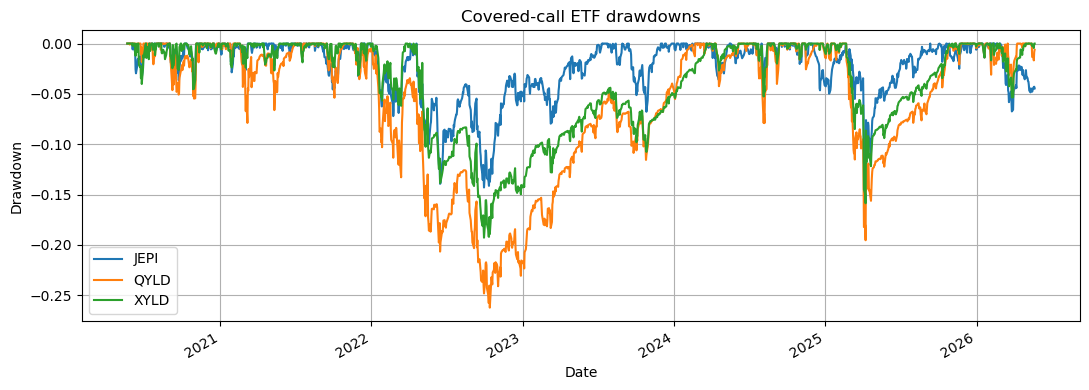

,Max drawdown
JEPI,-0.1430
QYLD,-0.2623
XYLD,-0.1928


NOTE: Yahoo price series may exclude distributions, so total return is understated for income ETFs.


In [15]:
available_etfs = [n for n in etf_tickers if n in prices.columns]
if available_etfs:
    etf_prices = prices[available_etfs].dropna(how='all').ffill()
    etf_returns = (100 * np.log(etf_prices / etf_prices.shift(1))).dropna()
    etf_summary = pd.DataFrame({
        'Mean daily %':   etf_returns.mean(),
        'Ann. return %':  etf_returns.mean() * 252,
        'Ann. vol %':     etf_returns.std() * np.sqrt(252),
        'Skewness':       etf_returns.skew(),
        'Excess kurtosis':etf_returns.kurtosis(),
    })
    display(etf_summary)
    cum = (1 + etf_returns/100).cumprod()
    cum.plot(title='Cumulative return of covered-call ETFs (price return, ex-distributions)')
    plt.ylabel('Growth of \u00a31'); plt.tight_layout(); plt.show()

    def drawdown(c): return c / c.cummax() - 1
    dd = cum.apply(drawdown)
    dd.plot(title='Covered-call ETF drawdowns'); plt.ylabel('Drawdown'); plt.tight_layout(); plt.show()
    display(pd.DataFrame({'Max drawdown': dd.min()}))
    print('NOTE: Yahoo price series may exclude distributions, so total return is understated for income ETFs.')
else:
    print('No covered-call ETF data available for the selected period.')

## 7. Interpretation guidance (map each result to a hypothesis and an article sentence)

- **H1 (clustering):** Significant Ljung-Box on squared returns + persistent ACF → reject constant variance → the article's premise that income depends on shifting volatility is well-founded.
- **H2 (leverage):** Report GJR $\theta$ and its t-stat from the parameter table; compare across underlyings. Larger, significant $\theta$ for Tesla supports the 'single-stock funds are riskier' caution.
- **H3 (level/persistence):** Higher annualised $V_L$ and persistence for Tesla → richer but more dangerous premiums, quantifying 'income uneven on volatile assets'.
- **H4 (sustainability):** Forecasts mean-revert toward $V_L$; the current-vs-long-run implied-yield gap formalises 'how long before your capital is eroded?' — high current yields decay → 'no free lunch' has a measurable basis.
- **Horse-race:** State which model wins on RMSE/QLIKE and what that implies about whether asymmetry aids *forecasting* (distinct from in-sample fit).
- Tie every number back to a sentence in the article — that is where comprehension and critical-evaluation marks are won.